# Web scraping e análise de sentimentos: Thomann Portuguesa
**Objetivo:** coletar produtos e comentários, identificar sentimento Positivo/Negativo e apresentar insights.

Coleta: **03/11/2026**. Entrega com dados reais coletados e resultados executados.
Abra este notebook na pasta do projeto, junto de `dados`.
As células usam o cache HTML incluído e não precisam de internet para reproduzir esta coleta.
Instalação, se necessário: `%pip install -r requirements.txt` (executar em célula própria).
Não há treinamento nesta abordagem; LeIA é uma linha de base lexical para português, com limitações demonstradas nesta amostra.

## 1. Escolha da loja, amostragem e método
Foram escolhidos três fones da Thomann Portuguesa: Superlux HD-681, Audio-Technica
ATH-M50X e beyerdynamic DT-770 Pro 80 Ohm. Coletaram-se as páginas disponíveis no filtro
português (reviewlang[]=6), ordenadas por data (order=latest), com limite de dez páginas
por produto e parada na última página incompleta. Há 67, 31 e 42 avaliações brutas,
respectivamente, totalizando 140 em 16 páginas HTML. São avaliações originais, sem tradução.

A extração usa requests e BeautifulSoup, intervalo de 1,5 s entre downloads, cache,
URLs, horários e hashes SHA-256. Reexecuções usam os HTMLs incluídos, sem novos downloads.
Não há login, APIs internas nem contorno de bloqueios.

O filtro do site também retornou textos em inglês. Por isso, além do atributo pt no HTML,
exigiu-se identificação pt pelo langdetect com valor >= 0,8 e semente fixa 0. Este valor é um
escore interno do detector, sem calibração como garantia de idioma. A regra conservadora
pode excluir comentários curtos em português. As decisões estão em dados/auditoria_idioma.csv.
Removeram-se espaços repetidos, vazios e duplicatas por produto/ID ou texto normalizado.

O sentimento é calculado pelo LeIA (Léxico para Inferência Adaptada), adaptação do VADER
ao português. Não se treinou um classificador supervisionado. Foram fixados o código,
os léxicos e a licença MIT do LeIA na pasta vendor, com referência ao commit original.
Há uma correção explícita na integração: a entrada lexical nao (-1,2) foi removida para
permitir sua atuação como operador de negação. Antes disso, a frase de teste com som não bom
recebia resultado positivo. Testes cobrem essa regressão e a leitura dos arquivos em UTF-8.
As demais regras do LeIA foram preservadas. A correção não elimina outras limitações do modelo.

O título e o comentário alimentam o modelo; estrelas nunca são entrada. O texto com acentos
fica preservado no CSV, embora o LeIA normalize acentos internamente. Preservam-se caixa,
pontuação e negações na entrada. O compound varia entre -1 e +1 e não é uma probabilidade.

Para a saída binária solicitada, compound >= 0 é Positivo e compound < 0 é Negativo.
Resultados com |compound| < 0,05 são sinalizados como baixa polaridade, incluindo zero,
atribuído a Positivo por convenção. Não são evidência firme de satisfação.

Na comparação auxiliar, 4–5 estrelas são referência positiva e 1–2, negativa. Três estrelas
ficam fora da comparação. Esses rótulos são fracos: notas e tom do texto podem divergir.
A matriz mede concordância com as estrelas e não acurácia validada por anotadores humanos.
O léxico também falha em expressões, negações complexas e termos técnicos de áudio.

In [1]:
"""Web scraping e análise de sentimentos de avaliações de fones na Thomann."""
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.parse import urlencode, urlparse
from urllib.robotparser import RobotFileParser
import hashlib
import json
import re
import time

import requests
from bs4 import BeautifulSoup
import pandas as pd
from langdetect import detect_langs, DetectorFactory, LangDetectException
from vendor.leia import SentimentIntensityAnalyzer

BASE = Path.cwd()
PRODUTOS = ['superlux_hd681', 'audio_technica_ath_m50_x', 'beyerdynamic_dt770_pro80_ohm']
AGENTE = 'EstudoAcademicoSentimentos/1.0'
LEIA = SentimentIntensityAnalyzer()
# No léxico original, "nao" tem peso -1,2 e impede a regra de negação das palavras seguintes.
# Removemos essa entrada para que o termo funcione como operador de negação.
LEIA.lexicon.pop("nao", None)
DetectorFactory.seed = 0


def identificar_idioma(texto):
    try:
        resultado = detect_langs(texto)[0]
        return dict(idioma_detectado=resultado.lang, confianca_idioma=resultado.prob)
    except LangDetectException:
        return dict(idioma_detectado='indeterminado', confianca_idioma=0.0)

## 2. Extração do HTML com BeautifulSoup
Cada bloco `.js-review` contém título, texto original, idioma e estrelas. A data é extraída sem exportar o nome do autor para o CSV. A nota vem da largura percentual das estrelas preenchidas.

In [2]:
def extrair_avaliacoes(html, url, coletado_em):
    soup = BeautifulSoup(html, 'html.parser')
    produto = soup.h1.get_text(' ', strip=True)
    rows = []
    for item in soup.select('.js-review'):
        corpo = item.select_one('.js-text-original')
        titulo = item.select_one('.js-headline-original')
        estrelas = item.select_one('.review-intro .fx-rating-stars__filler')
        autor_data = item.select_one('.review-intro__author')
        if corpo is None:
            continue
        nota = None
        if estrelas:
            pct = re.search(r'width:\s*([\d.]+)%', estrelas.get('style', ''))
            if pct:
                nota = float(pct[1]) / 20
        data = re.search(r'\b(\d{2}\.\d{2}\.\d{4})\b', autor_data.get_text() if autor_data else '')
        rows.append(dict(produto=produto, review_id=item.get('data-rating-id'),
                         titulo=titulo.get_text(' ', strip=True) if titulo else '',
                         comentario=corpo.get_text(' ', strip=True), idioma=corpo.get('lang', ''),
                         nota=nota, data_avaliacao=datetime.strptime(data[1], '%d.%m.%Y').date().isoformat() if data else None,
                         url_origem=url, coletado_em=coletado_em))
    return rows

## 3. Coleta, cache e rastreabilidade
As URLs incluem produto, página, ordenação e idioma. O manifesto guarda horário e SHA-256 de cada HTML. Com o cache completo, esta etapa apenas reprocessa arquivos locais. Para uma nova coleta independente, use uma cópia desta pasta sem o diretório `dados/html`; preserve a coleta entregue.

In [3]:
def coletar(paginas=10):
    """Cache e pausa de 1,5 s; sem login, APIs internas ou contorno de bloqueios."""
    cache = BASE / 'dados' / 'html'
    cache.mkdir(parents=True, exist_ok=True)
    sessao = requests.Session()
    sessao.headers['User-Agent'] = AGENTE
    dominio = 'https://www.thomann.pt'
    robots_path = cache / 'robots.txt'
    if not robots_path.exists():
        r = sessao.get(dominio + '/robots.txt', timeout=40)
        r.raise_for_status()
        robots_path.write_text(r.text, encoding='utf-8')
    robots = RobotFileParser()
    robots.parse(robots_path.read_text(encoding='utf-8').splitlines())
    registros, manifesto = [], []
    for slug in PRODUTOS:
        ids_vistos = set()
        for pagina in range(1, paginas + 1):
            url = f'{dominio}/{slug}_reviews.htm?' + urlencode({'page': pagina, 'order': 'latest', 'reviewlang[]': 6})
            if not robots.can_fetch(AGENTE, url):
                raise RuntimeError(f'Coleta interrompida pelo robots.txt: {url}')
            arquivo = cache / f'{slug}_{pagina:02}.html'
            meta = arquivo.with_suffix('.json')
            if not arquivo.exists():
                time.sleep(1.5)
                r = sessao.get(url, timeout=40)
                r.raise_for_status()
                if urlparse(r.url).netloc != urlparse(url).netloc:
                    raise RuntimeError('Redirecionamento para outro domínio; revisar antes de continuar.')
                html = r.content.decode('utf-8')
                rows = extrair_avaliacoes(html, url, '')
                if not rows:
                    raise RuntimeError(f'Nenhuma avaliação: possível alteração do HTML em {url}')
                arquivo.write_text(html, encoding='utf-8')
                meta.write_text(json.dumps(dict(url=url, coletado_em=datetime.now(ZoneInfo('America/Sao_Paulo')).isoformat(),
                                               sha256=hashlib.sha256(arquivo.read_bytes()).hexdigest()), indent=2), encoding='utf-8')
            info = json.loads(meta.read_text(encoding='utf-8'))
            html = arquivo.read_text(encoding='utf-8')
            assert hashlib.sha256(arquivo.read_bytes()).hexdigest() == info['sha256'], 'Cache alterado'
            rows = extrair_avaliacoes(html, info['url'], info['coletado_em'])
            novos = {x['review_id'] for x in rows} - ids_vistos
            if not novos:
                break  # Detecta última página ou servidor ignorando a paginação.
            ids_vistos.update(novos)
            registros.extend(rows)
            manifesto.append(dict(arquivo=arquivo.name, **info, n_extraidas=len(rows)))
            print(f'{slug}: página {pagina}, {len(rows)} avaliações', flush=True)
            if len(rows) < 10:
                break
    df = pd.DataFrame(registros)
    df.to_csv(BASE / 'dados' / 'avaliacoes_brutas.csv', index=False, encoding='utf-8-sig')
    (BASE / 'dados' / 'manifesto.json').write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding='utf-8')
    return df

In [4]:
brutas = coletar(paginas=10)
print("Registros brutos:", len(brutas))
brutas[["produto", "review_id", "nota", "idioma", "data_avaliacao"]].head()

superlux_hd681: página 1, 10 avaliações


superlux_hd681: página 2, 10 avaliações


superlux_hd681: página 3, 10 avaliações


superlux_hd681: página 4, 10 avaliações


superlux_hd681: página 5, 10 avaliações


superlux_hd681: página 6, 10 avaliações


... (8 outputs left out)

beyerdynamic_dt770_pro80_ohm: página 4, 10 avaliações


beyerdynamic_dt770_pro80_ohm: página 5, 2 avaliações


Registros brutos: 140


,produto,review_id,nota,idioma,data_avaliacao
0,Superlux HD-681,5702013,4.0,pt,2026-04-28
1,Superlux HD-681,5507238,5.0,pt,2025-09-16
2,Superlux HD-681,5432278,5.0,pt,2025-06-04
3,Superlux HD-681,5397115,5.0,pt,2025-04-19
4,Superlux HD-681,5384204,5.0,pt,2025-04-03


## 4. Classificação e limpeza
Preservamos o texto original para não apagar as pistas que LeIA utiliza. A classificação usa somente título e comentário. `baixa_polaridade` sinaliza resultados próximos de zero; o desempate em zero é positivo por convenção binária.

In [5]:
def classificar(texto):
    score = LEIA.polarity_scores(texto)['compound']
    return dict(score=score, sentimento='Positivo' if score >= 0 else 'Negativo',
                baixa_polaridade=abs(score) < 0.05)

def analisar(brutas):
    df = brutas.copy()
    df['comentario'] = df.comentario.fillna('').str.replace(r'\s+', ' ', regex=True).str.strip()
    n_inicial = len(df)
    idiomas = pd.DataFrame(df.comentario.map(identificar_idioma).tolist())
    df = pd.concat([df.reset_index(drop=True), idiomas], axis=1)
    df['incluir_idioma'] = df.idioma.eq('pt') & df.idioma_detectado.eq('pt') & df.confianca_idioma.ge(0.8)
    df.to_csv(BASE / 'dados' / 'auditoria_idioma.csv', index=False, encoding='utf-8-sig')
    n_excluidas_idioma = int((~df.incluir_idioma).sum())
    df = df[df.incluir_idioma & df.comentario.ne('')].copy()
    df = df.drop_duplicates(['produto', 'review_id'])
    df['texto_normalizado'] = (df.titulo.fillna('') + ' ' + df.comentario).str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
    df = df.drop_duplicates(['produto', 'texto_normalizado']).reset_index(drop=True)
    df['texto_analisado'] = df.titulo.fillna('') + '. ' + df.comentario
    scores = pd.DataFrame(df.texto_analisado.map(classificar).tolist())
    df = pd.concat([df, scores], axis=1)
    df['referencia_estrelas'] = df.nota.map(lambda x: 'Positivo' if x >= 4 else ('Negativo' if x <= 2 else 'Sem referência'))
    df['divergencia'] = df.referencia_estrelas.ne('Sem referência') & df.sentimento.ne(df.referencia_estrelas)
    df.to_csv(BASE / 'dados' / 'avaliacoes_classificadas.csv', index=False, encoding='utf-8-sig')
    resumo = df.groupby('produto').agg(avaliacoes=('score', 'size'), positivos=('sentimento', lambda x: x.eq('Positivo').sum()),
        negativos=('sentimento', lambda x: x.eq('Negativo').sum()), nota_media=('nota', 'mean'), score_medio=('score', 'mean'))
    resumo['percentual_positivo'] = 100 * resumo.positivos / resumo.avaliacoes
    resumo.to_csv(BASE / 'dados' / 'resumo_produtos.csv', encoding='utf-8-sig')
    ref = df[df.referencia_estrelas.ne('Sem referência')]
    matriz = pd.crosstab(ref.referencia_estrelas, ref.sentimento).reindex(index=['Negativo', 'Positivo'], columns=['Negativo', 'Positivo'], fill_value=0)
    matriz.to_csv(BASE / 'dados' / 'matriz_estrelas.csv', encoding='utf-8-sig')
    metricas = dict(n_brutas=n_inicial, n_validas=len(df), n_removidas=n_inicial-len(df),
        n_excluidas_idioma=n_excluidas_idioma,
        positivos=int(df.sentimento.eq('Positivo').sum()), negativos=int(df.sentimento.eq('Negativo').sum()),
        baixa_polaridade=int(df.baixa_polaridade.sum()), referencia_n=len(ref),
        referencia_negativos=int(ref.referencia_estrelas.eq('Negativo').sum()),
        concordancia_estrelas=float(ref.sentimento.eq(ref.referencia_estrelas).mean()), divergencias=int(df.divergencia.sum()))
    (BASE / 'dados' / 'metricas.json').write_text(json.dumps(metricas, indent=2), encoding='utf-8')
    return df, resumo, matriz, metricas

In [6]:
df, resumo, matriz, metricas = analisar(brutas)
assert not df.duplicated(["produto", "review_id"]).any()
assert df.sentimento.isin(["Positivo", "Negativo"]).all()
assert df.score.between(-1, 1).all()
assert df.idioma.eq("pt").all()
assert df.nota.between(1, 5).all()
print(json.dumps(metricas, indent=2, ensure_ascii=False))
resumo.round(3)

{
  "n_brutas": 140,
  "n_validas": 124,
  "n_removidas": 16,
  "n_excluidas_idioma": 16,
  "positivos": 106,
  "negativos": 18,
  "baixa_polaridade": 7,
  "referencia_n": 119,
  "referencia_negativos": 1,
  "concordancia_estrelas": 0.8571428571428571,
  "divergencias": 17
}


,avaliacoes,positivos,negativos,nota_media,score_medio,percentual_positivo
produto,,,,,,
Audio-Technica ATH-M50X,28,26,2,4.929,0.561,92.857
Superlux HD-681,60,49,11,4.517,0.442,81.667
beyerdynamic DT-770 Pro 80 Ohm,36,31,5,4.917,0.530,86.111


## 5. Distribuição de sentimentos e comparação por produto

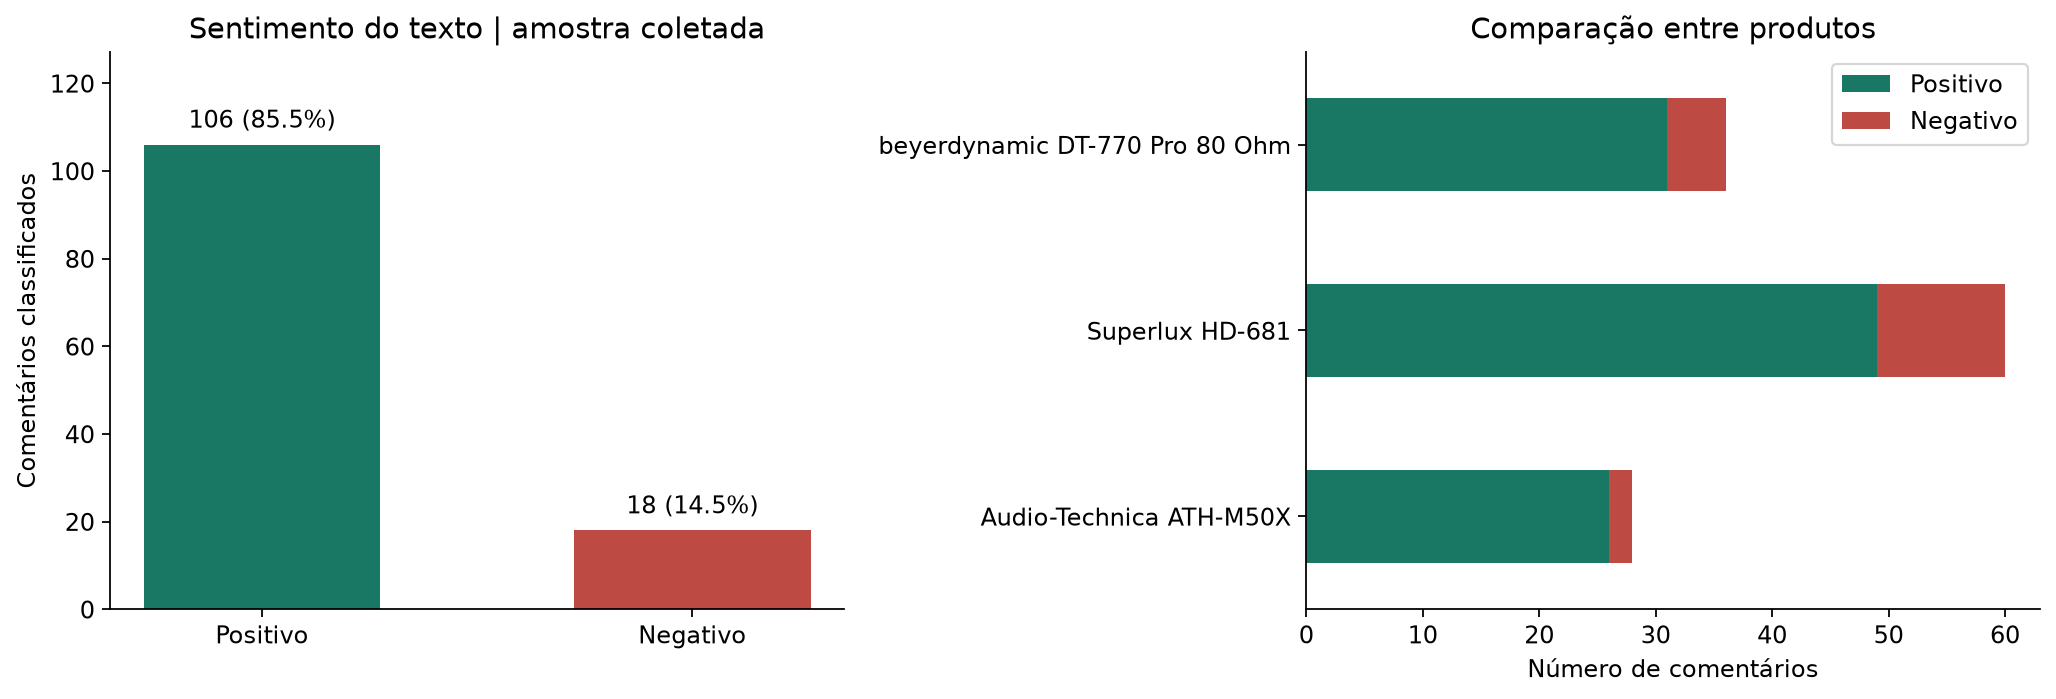

In [7]:
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from IPython.display import display, Image
OUT = BASE / "resultados"
OUT.mkdir(exist_ok=True)
m = metricas
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
cores = ['#187864', '#bd4b43']

def salvar(fig, nome):
    fig.savefig(OUT / nome, dpi=160, bbox_inches='tight', facecolor='white')
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cont = df.sentimento.value_counts().reindex(['Positivo','Negativo'], fill_value=0)
bars = axes[0].bar(cont.index, cont.values, color=cores, width=.55)
axes[0].bar_label(bars, labels=[f'{n} ({n/len(df):.1%})' for n in cont.values], padding=5)
axes[0].set_ylim(0, max(cont.values)*1.2)
axes[0].set_ylabel('Comentários classificados')
axes[0].set_title('Sentimento do texto | amostra coletada')
resumo[['positivos','negativos']].rename(columns={'positivos':'Positivo','negativos':'Negativo'}).plot.barh(stacked=True, color=cores, ax=axes[1])
axes[1].set_ylabel('')
axes[1].set_xlabel('Número de comentários')
axes[1].set_title('Comparação entre produtos')
fig.tight_layout()
salvar(fig, 'sentimentos.png')

fig, ax = plt.subplots(figsize=(6, 4.7))
ax.imshow(matriz.values, cmap='Blues')
ax.set_xticks([0,1], ['Negativo','Positivo'])
ax.set_yticks([0,1], ['Negativo (1–2 estrelas)','Positivo (4–5 estrelas)'])
ax.set_xlabel('Previsto pelo texto (LeIA)')
ax.set_ylabel('Referência aproximada pelas estrelas')
ax.set_title('Concordância com as estrelas\nNão equivale a validação humana')
for (i,j), v in __import__('numpy').ndenumerate(matriz.values):
    ax.text(j,i,str(v),ha='center',va='center',color='white' if v>matriz.values.max()/2 else '#172333',fontsize=18)
salvar(fig, 'matriz_estrelas.png')

# Frequência documental: cada termo conta no máximo uma vez por comentário.
neg = df.loc[df.sentimento.eq('Negativo'), 'comentario']
if len(neg):
    vec = CountVectorizer(stop_words='a o os as um uma de do da dos das e ou que para por com no na nos nas em se ao aos eu me meu minha muito mais este estes esta estas sao foi ser tem como mas nao'.split(), binary=True, min_df=1)
    X = vec.fit_transform(neg)
    termos = pd.Series(X.sum(axis=0).A1, index=vec.get_feature_names_out()).sort_values(ascending=False).head(15)
    termos.rename_axis('termo').rename('comentarios_negativos_com_termo').to_csv(OUT/'termos_negativos.csv', encoding='utf-8-sig')
    fig,ax=plt.subplots(figsize=(8,5))
    termos.sort_values().plot.barh(ax=ax, color='#bd4b43')
    ax.set_xlabel('Comentários negativos que mencionam o termo')
    ax.set_title('Termos frequentes nos textos classificados como negativos\nMenção não determina sentimento sobre o aspecto')
    salvar(fig, 'termos_negativos.png')

display(Image(filename=str(OUT / "sentimentos.png")))

## 6. Comparação com estrelas (referência fraca)
Linhas: referência por estrelas; colunas: classificação pelo texto. Três estrelas ficam fora desta comparação. Esses resultados não são uma acurácia validada por anotadores.

sentimento,Negativo,Positivo
referencia_estrelas,,
Negativo,0,1
Positivo,16,102


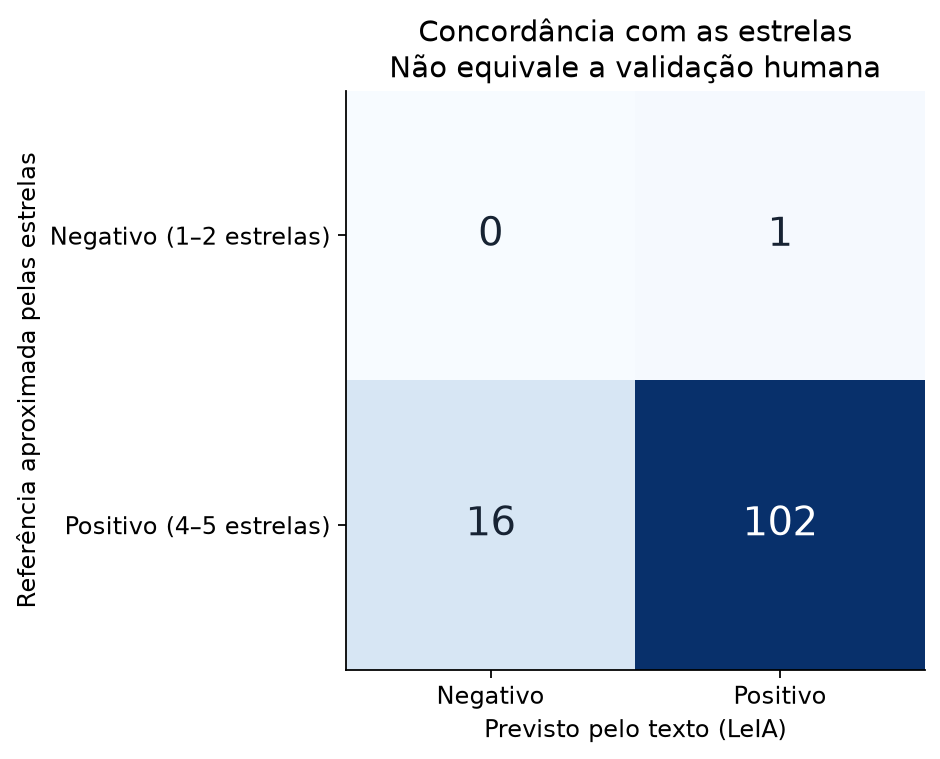

In [8]:
display(matriz)
display(Image(filename=str(BASE / "resultados" / "matriz_estrelas.png")))

## 7. Exemplos verificáveis
A tabela contém comentários negativos e divergências para inspeção. O texto completo, ID e URL estão no CSV; a tabela abaixo mostra trechos de até 180 caracteres.

In [9]:
exemplos = pd.concat([df[df.sentimento.eq("Negativo")].head(6), df[df.divergencia].head(6)]).drop_duplicates(["produto", "review_id"])
exemplos = exemplos.assign(trecho=exemplos.comentario.str[:180])
exemplos[["produto", "review_id", "nota", "score", "sentimento", "trecho"]]

,produto,review_id,nota,score,sentimento,trecho
16,Superlux HD-681,4639059,4.0,-0.2960,Negativo,Dá para Aguentar na captação de instrumento e ...
17,Superlux HD-681,4582503,3.0,-0.2093,Negativo,São uns headphones semi-abertos com fio o norm...
19,Superlux HD-681,4508250,4.0,-0.7269,Negativo,Já comprei estes fones à 5 anos e ainda hoje o...
25,Superlux HD-681,4336883,4.0,-0.2626,Negativo,"Depois de algumas horas a usar, incomoda basta..."
29,Superlux HD-681,4224439,4.0,-0.2992,Negativo,Pelo seu preço não se pode pedir muito. No meu...
40,Superlux HD-681,3505487,5.0,-0.6808,Negativo,"Muito bons. Uso para praticar viola baixo, qua..."
23,Superlux HD-681,4448813,2.0,0.2235,Positivo,Este artigo não serve minimamente para o efeit...


## 8. Temas e frequência documental
Os temas usam expressões explícitas; o mesmo comentário pode mencionar vários temas. A coluna em_textos_negativos descreve a polaridade global do comentário, sem inferir sentimento sobre cada aspecto.

,tema,comentarios_com_mencao,em_textos_negativos
0,Som,95,10
1,Conforto,66,9
2,Construção e durabilidade,27,4
3,Preço e valor,55,6


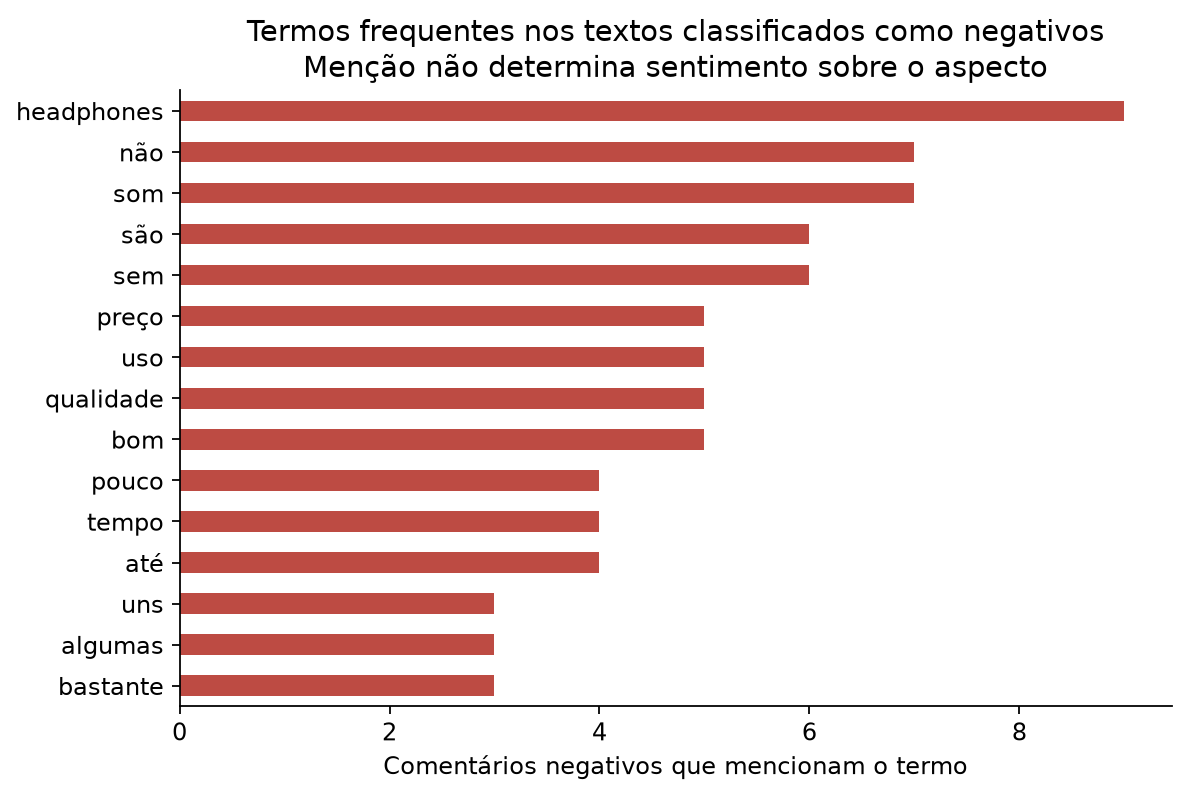

In [10]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    temas = {'Som': '\\b(?:som|audio|áudio|graves?|agudos?|frequências?|frequencias?|sonor\\w*)\\b', 'Conforto': '\\b(?:confort\\w*|desconfort\\w*|orelhas?|almofadas?|apert\\w*|pesad\\w*)\\b', 'Construção e durabilidade': '\\b(?:constru\\w*|dur\\w*|cabo|cabos|plástico|plastico|quebr\\w*|desgast\\w*)\\b', 'Preço e valor': '\\b(?:preço|preços|preco|precos|barat\\w*|caro|caros|valor|custo)\\b'}
    temas_resultado = []
    for tema, rx in temas.items():
        menciona = df.comentario.str.contains(rx, case=False, regex=True)
        temas_resultado.append({"tema": tema, "comentarios_com_mencao": int(menciona.sum()), "em_textos_negativos": int((menciona & df.sentimento.eq("Negativo")).sum())})
display(pd.DataFrame(temas_resultado))
display(Image(filename=str(BASE / "resultados" / "termos_negativos.png")))

## 9. Insights e limitações
A amostra contém **124 comentários válidos**, sendo **106 positivos
(85.5%)** e **18 negativos (14.5%)**. Foram excluídos
16 registros pelo critério adicional de idioma; a base bruta tem 140 registros. Há 7 textos de baixa polaridade.

O maior percentual positivo observado foi o de **Audio-Technica ATH-M50X**
(92.9%, n=28).
Esse resultado descreve a janela coletada; não demonstra superioridade do produto.
O número de comentários e o período coberto devem acompanhar qualquer comparação.

Na referência de 119 avaliações de 1–2 ou 4–5 estrelas,
a concordância foi **85.7%**, com 17 divergências.
Quantidade de referências negativas nessa comparação: 1;
o desbalanceamento exige examinar a matriz e impede tratar a concordância global como prova de qualidade.

A leitura exploratória dos comentários 4508250 e 4336883 do Superlux mostra elogios ao som
acompanhados de desconforto depois de horas de uso, mesmo com quatro estrelas.
No ATH-M50X, o comentário 4955954 também cita o peso como limitador do tempo de uso.
São exemplos que sugerem investigar ergonomia e duração das sessões, sem medir a
prevalência de cada problema na população de compradores.

Há falsos negativos plausíveis: o comentário 3505487 elogia a definição das frequências
graves, mas o classificador retorna negativo. O léxico pode interpretar termos técnicos
como palavras de polaridade. Já o 2730701 recomenda o produto e nega haver aspectos
negativos, mas também recebe classificação negativa. Esses casos mostram que os
percentuais calculados não devem ser usados diretamente como taxa de insatisfação.

Como referência de desbalanceamento, prever sempre Positivo concordaria com
99.2% das estrelas elegíveis.
Essa referência supera a concordância do LeIA nesta amostra; o modelo lexical não está
validado para decisões sobre reclamações. A presença de apenas uma referência negativa
também impede conclusões robustas sobre sua capacidade de reconhecer insatisfação.

As tabelas de temas e termos ajudam a priorizar a leitura: som, conforto, construção/durabilidade
e preço podem aparecer tanto em elogios quanto em reclamações. As contagens de menções não são
uma análise de sentimento por aspecto e os temas podem se sobrepor.

Como ação prática, recomenda-se revisar primeiro as divergências com as estrelas e os textos de
baixa polaridade. Depois, categorizar manualmente as reclamações de conforto, peso e construção
antes de propor melhorias, devoluções ou mudanças na descrição do produto.

Esta é uma amostra por conveniência, limitada ao português e às páginas disponíveis no momento.
Não é uma estimativa representativa de todos os compradores, das vendas ou do mercado.
Comentários de várias datas podem aparecer nas páginas mais recentes; não há inferência causal.
Uma evolução seria construir uma amostra anotada por duas pessoas e medir precisão, recall e F1
por classe em dados independentes, comparando LeIA com Naive Bayes ou outro modelo.

## 10. Referências
- Loja e páginas de avaliações: https://www.thomann.pt/superlux_hd681_reviews.htm ; https://www.thomann.pt/audio_technica_ath_m50_x_reviews.htm ; https://www.thomann.pt/beyerdynamic_dt770_pro80_ohm_reviews.htm
- Regras consultadas: https://www.thomann.pt/robots.txt (cópia na pasta dados/html).
- LeIA: Rafael J. A. Almeida (2018). https://github.com/rafjaa/LeIA (commit fixado em vendor/ORIGEM.md).
- VADER, base original do LeIA: Hutto, C. J.; Gilbert, E. (2014). *VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text*. ICWSM. https://github.com/cjhutto/vaderSentiment
- langdetect: https://pypi.org/project/langdetect/
- BeautifulSoup: https://www.crummy.com/software/BeautifulSoup/bs4/doc/
- Material de apoio fornecido: “Aula 05 — Data Scraping com BeautifulSoup”, Renato Vimieiro (2017), e “Análise de sentimentos — Utilizando Python para construir e treinar modelos de machine learning”, Wheslley Rimar Bezerra. Foram usados como referências didáticas; os exercícios e procedimentos do material não substituem o pedido do usuário. Aqui foi escolhida uma abordagem lexical, com avaliação auxiliar por estrelas, em vez de reproduzir o treino supervisionado do PDF.